   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

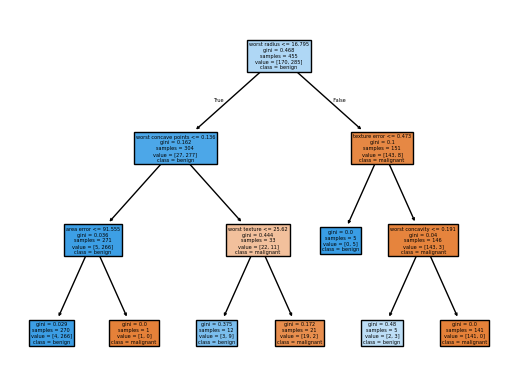

[0 1 0 1 0 1 1 0 0 0]
Classes: ['malignant' 'benign']
Logistic accuracy: 0.9824561403508771
Tree accuracy: 0.9385964912280702
Before: target
1    285
0    170
Name: count, dtype: int64
After: target
1    285
0    285
Name: count, dtype: int64


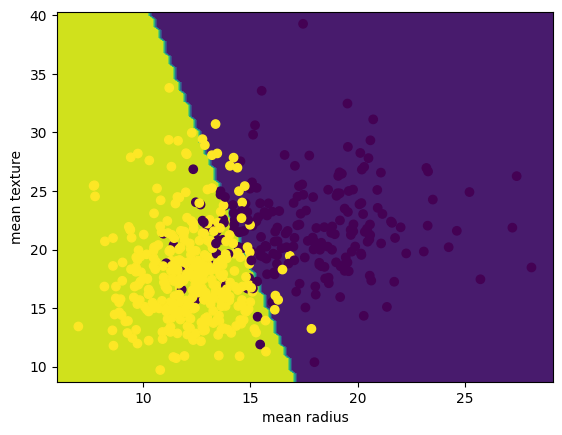

Accuracy: 0.9824561403508771
Precision: 0.9824561403508771
Recall: 0.9824561403508771
F1: 0.9824561403508771


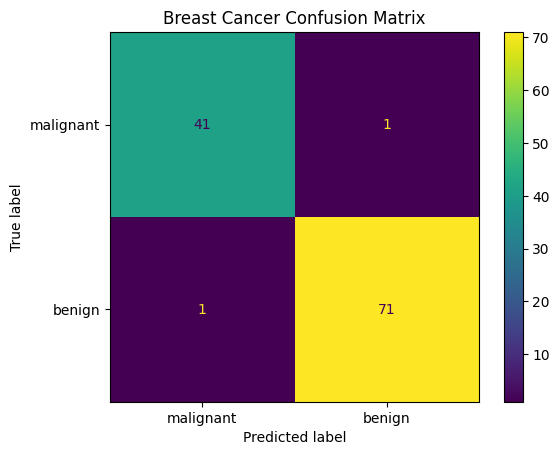

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.datasets import load_breast_cancer
iris = load_iris(as_frame=True)
iris_df = iris.frame
Xc = iris_df.drop(columns=["target"])
yc = iris.target
print(Xc.head())
print(iris.target_names)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
Xtr, Xte, ytr, yte = train_test_split(
    Xc, yc, test_size=0.2,
    random_state=42, stratify=yc
)
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
log_model.fit(Xtr, ytr)
pred_log = log_model.predict(Xte)
print(pred_log[:10])
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
knn.fit(Xtr, ytr)
pred_knn = knn.predict(Xte)
print(pred_knn[:10])
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(Xtr, ytr)
pred_nb = nb.predict(Xte)
print(pred_nb[:10])
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree = DecisionTreeClassifier(
max_depth=3, random_state=42
)
tree.fit(Xtr, ytr)
pred_tree = tree.predict(Xte)
plot_tree(tree, feature_names=Xc.columns,
class_names=iris.target_names,
filled=True)
plt.show()
from sklearn.svm import SVC
svm = make_pipeline(
StandardScaler(),
SVC(kernel="rbf")
)
svm.fit(Xtr, ytr)
pred_svm = svm.predict(Xte)
print(pred_svm[:10])
from sklearn.metrics import accuracy_score
print("Classes:", iris.target_names)
print("Logistic accuracy:",
accuracy_score(yte, pred_log))
print("Tree accuracy:",
accuracy_score(yte, pred_tree))
from sklearn.linear_model import LogisticRegression
weighted = LogisticRegression(
class_weight="balanced",
max_iter=2000
)
# %pip install imbalanced-learn
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(
X_train_encoded, y_train
)
print("Before:", y_train.value_counts())
print("After:", pd.Series(y_res).value_counts())
from sklearn.inspection import DecisionBoundaryDisplay
X2 = Xc[["petal length (cm)",
"petal width (cm)"]]
boundary_model = make_pipeline(
StandardScaler(),
LogisticRegression(max_iter=2000)
)
boundary_model.fit(X2, yc)
DecisionBoundaryDisplay.from_estimator(
boundary_model, X2,
response_method="predict",
plot_method="contourf"
)
plt.scatter(X2.iloc[:,0], X2.iloc[:,1], c=yc)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.show()
from sklearn.metrics import (
accuracy_score, precision_score,
recall_score, f1_score
)
print("Accuracy:", accuracy_score(yte,pred_log))
print("Precision:", precision_score(
yte,pred_log,average="weighted"))
print("Recall:", recall_score(
yte,pred_log,average="weighted"))
print("F1:", f1_score(
yte,pred_log,average="weighted"))
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    yte, pred_log,
    display_labels=iris.target_names
)
plt.title("Iris Confusion Matrix")
plt.show()

In [ ]:

Afas Afas <aafas317@gmail.com>
3:07 PM (0 minutes ago)
to Hansikaa

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100, random_state=42
)
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

scores = cross_val_score(
    model, X_train, y_train, cv=cv, scoring="accuracy"
)
print("Fold scores:", scores.round(3))
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

grid = {
    "n_estimators": [50, 100],
    "max_depth": [None, 3, 5]
}
search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    grid, cv=5, scoring="accuracy"
)
search.fit(Xc_train, yc_train)

print(search.best_params_)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

models = {
 "Baseline": LogisticRegression(max_iter=1000),
 "Bagging-style": RandomForestClassifier(n_estimators=100, random_state=42),
 "Boosting": GradientBoostingClassifier(random_state=42)
}

for name, clf in models.items():
    clf.fit(Xc_train, yc_train)
    pred = clf.predict(Xc_test)
    print(name, round(accuracy_score(yc_test, pred), 3))


Fold scores: [0.967 0.956 0.934 0.967 0.989]
Best params: {'max_depth': None, 'n_estimators': 100}


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Baseline 0.965
Bagging-style 0.956
Boosting 0.956
